<div style="border:solid Chocolate 2px; padding: 40px">

<b>Привет!</b>

Меня зовут Евгений Головин, я буду ревьюером твоего проекта. Если ты не против, то предлагаю построить наше общение на "ты" ;) Если удобнее на "вы", то нет проблем, только скажи об этом.

В ходе работы я оставил тебе комментарии <font color='green'>зеленого</font>, <font color='gold'>желтого</font> и <font color='red'>красного</font> цветов. Сейчас объясню, что они значат:

<br/>

<div class="alert alert-success">
<h2> Комментарий ревьюера <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Решение на этом шаге является полностью правильным.
</div>

<br/>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Решение на этом шаге станет еще лучше, если внести небольшие коррективы.
</div>


<br/>
<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера <a class="tocSkip"></h2>


<b>На доработку🤔:</b>
 Решение на этом шаге требует существенной переработки и внесения правок. Напоминаю, что проект не может быть принят с первого раза, если ревью содержит комментарии, рекомендующие доработать шаги.
</div>

Увидев мой комментарий, не удаляй его, он будет очень полезен в случае повторной проверки работы :)

<div class="alert alert-info">
<b>А свой помечай вот так, чтобы я его не потерял ;)</b>
</div>

На мои комменатрии можно и нужно реагировать, только делать это стоит так, чтобы твои и мои комменты не смешались: выделяй свои цветами, сильно отличающимися от моих.

Увидев у тебя неточность, в первый раз я лишь укажу на ее наличие и дам тебе возможность самому найти и исправить ее. На реальной работе твой руководитель будет поступать также, и я пытаюсь подготовить тебя именно к работе аналитиком. Но если ты пока не справишься с такой задачей - при следующей проверке я дам более точную подсказку!
</div>

<div class="alert alert-info">
<b>Евгений, спасибо большое за такоё подробное ревью ;)</b>
</div>

# Предсказание покупки в течение 90 дней

**Задача.** Интернет-магазин одежды хочет заранее выделять клиентов, готовых совершить
покупку в ближайшие 90 дней, чтобы точнее таргетировать рассылки. Нужно построить модель
бинарной классификации и максимизировать **ROC-AUC**.

**Данные.**
- `apparel-purchases` — история покупок (клиент, товар, цена, количество, категории, дата);
- `apparel-messages` — история рассылок (событие: send/open/click/purchase/…, канал, дата);
- `apparel-target_binary` — целевая метка: совершит ли клиент покупку в следующие 90 дней;
- `full_campaign_daily_event(_channel)` — агрегированная по дням статистика кампаний.

**План.** EDA → определение временной границы → признаки (RFM по покупкам, категории,
поведение в рассылках) → базовые модели и кросс-валидация → тюнинг → финальная оценка на
отложенной выборке → проверка на утечку.

## 1. Импорты и конфигурация

In [1]:
import ast
import os
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42
N_JOBS = 2
DATA_DIR = Path(os.environ.get("DATA_DIR", "filtered_data")).expanduser()
REQUIRED_FILES = ["apparel-purchases.csv", "apparel-messages.csv",
                  "apparel-target_binary.csv", "full_campaign_daily_event.csv",
                  "full_campaign_daily_event_channel.csv"]
missing_files = [name for name in REQUIRED_FILES if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        f"В папке {DATA_DIR.resolve()} отсутствуют {missing_files}. "
        "Поместите CSV в ./filtered_data или задайте переменную окружения DATA_DIR.")

## 2. Загрузка и первичный обзор

Таблицы покупок и таргета небольшие, читаем целиком. Файл рассылок большой (~1.4 ГБ),
поэтому его будем обрабатывать чанками на этапе построения признаков.

In [2]:
purchases = pd.read_csv(f"{DATA_DIR}/apparel-purchases.csv",
                        dtype={"client_id": str}, parse_dates=["date"])
target = pd.read_csv(f"{DATA_DIR}/apparel-target_binary.csv", dtype={"client_id": str})

print("purchases:", purchases.shape)
print("target:   ", target.shape)
purchases.head()

purchases: (202208, 6)
target:    (49849, 2)


,client_id,quantity,price,category_ids,date,message_id
0,1515915625468169594,1,1999.0,"['4', '28', '57', '431']",2022-05-16,1515915625468169594-4301-627b661e9736d
1,1515915625468169594,1,2499.0,"['4', '28', '57', '431']",2022-05-16,1515915625468169594-4301-627b661e9736d
2,1515915625471138230,1,6499.0,"['4', '28', '57', '431']",2022-05-16,1515915625471138230-4437-6282242f27843
3,1515915625471138230,1,4999.0,"['4', '28', '244', '432']",2022-05-16,1515915625471138230-4437-6282242f27843
4,1515915625471138230,1,4999.0,"['4', '28', '49', '413']",2022-05-16,1515915625471138230-4437-6282242f27843


In [3]:
print("Период покупок:", purchases['date'].min().date(), "->", purchases['date'].max().date())
print("Уникальных клиентов в покупках:", purchases['client_id'].nunique())
print("Уникальных клиентов в таргете: ", target['client_id'].nunique())
print("\nБаланс классов:")
print(target['target'].value_counts(normalize=True).round(4))

Период покупок: 2022-05-16 -> 2024-02-16
Уникальных клиентов в покупках: 49849
Уникальных клиентов в таргете:  49849

Баланс классов:
target
0    0.9807
1    0.0193
Name: proportion, dtype: float64


Классы сильно несбалансированы: доля положительного класса ≈ **1.9%**. Все клиенты из таргета
присутствуют в истории покупок, то есть это «действующие» покупатели, и мы предсказываем их
повторную покупку. Несбалансированность учтём через `class_weight="balanced"` и метрику ROC-AUC
(она устойчива к дисбалансу).

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Отличное начало: короткая постановка, описание всех таблиц и план работы — сразу понятно, куда движется проект, и уже на этом этапе видно, что ты держишь в голове главный риск задачи, утечку. Загрузка сделана аккуратно: `client_id` читается как строка (длинные id в этом датасете при чтении «по умолчанию» превращаются во float и теряют точность — очень частая ошибка, у тебя её нет), даты парсятся сразу при чтении, а тяжёлый файл рассылок ты сознательно не грузишь целиком. Вывод про дисбаланс (≈1.9%) и выбор `class_weight="balanced"` + ROC-AUC — верные.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> `DATA_DIR` — абсолютный путь с конкретного компьютера, у любого другого человека тетрадка упадёт на первой же ячейке чтения. Лучше относительный путь (например, `./data`) или переменная окружения плюс проверка `os.path.exists` с понятным сообщением об ошибке.
</div>

<div class="alert alert-info">
<b>Комментарий студента — отработка замечания v1</b><br>
Путь заменён на относительный ./filtered_data с возможностью задать DATA_DIR через окружение. Перед чтением проверяется наличие всех пяти CSV; ошибка содержит список отсутствующих файлов.
</div>

<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера v1<a class="tocSkip"></h2>

<b>На доработку🤔:</b> Исследовательского анализа данных по сути нет, хотя в плане EDA стоит первым пунктом. Размер, период, число клиентов и баланс классов — это паспорт данных, а не их анализ. До построения признаков нужно посмотреть на сами данные и сделать по ним выводы, которые потом обоснуют твои решения. Как минимум:

- проверь таблицы покупок и рассылок на полные дубликаты и реши, что с ними делать (обрати внимание, что `p_n_tx` у тебя считает именно строки);
- посмотри на распределения `price` и `quantity` и на аномальные значения — например, в собранной таблице ниже у одного из первых клиентов `p_min_price = 7.0`. Это нормально для магазина одежды?
- распределение числа покупок на клиента (сколько клиентов купили один раз — это важно для интерпретации признаков);
- обзор `apparel-messages`: период, распределение `event` и `channel`, доля клиентов без рассылок;
- таблицы `full_campaign_daily_event*` перечислены в данных, но даже не загружены — нужно хотя бы взглянуть на них и объяснить, почему ты их не используешь.

Несколько графиков и короткий вывод после каждого блока будет достаточно. Файл рассылок можно исследовать тем же чанковым подходом, который ты уже написал(а) в разделе 5.
</div>

<div class="alert alert-info">
<b>Комментарий студента — отработка замечания v1</b><br>
Добавлен полный EDA до признаков: пропуски и совпадения строк, цены и количества, частота строк и дней покупок, полный чанковый обзор событий/каналов рассылок и отсутствия рассылок у клиентов. Обе таблицы кампаний загружены и проверены. Выводы и решения по совпадениям и экстремальным ценам приведены после блоков; обнаружены будущие даты в агрегатах кампаний, поэтому они исключены из модели.
</div>

### 2.1. Покупки: качество данных и распределения

,Пропуски
client_id,0
quantity,0
price,0
category_ids,0
date,0
message_id,0


Полных совпадений строк покупок: 73,020 (36.1%)


,price,quantity
count,202208.000000,202208.000000
mean,1193.301516,1.006483
std,1342.252664,0.184384
min,1.000000,1.000000
1%,3.000000,1.000000
50%,987.000000,1.000000
99%,5499.000000,1.000000
99.9%,13050.545000,2.000000
max,85499.000000,30.000000


Некорректных строк: 0
Строк с ценой < 10: 7924
Строк с количеством > 1: 885


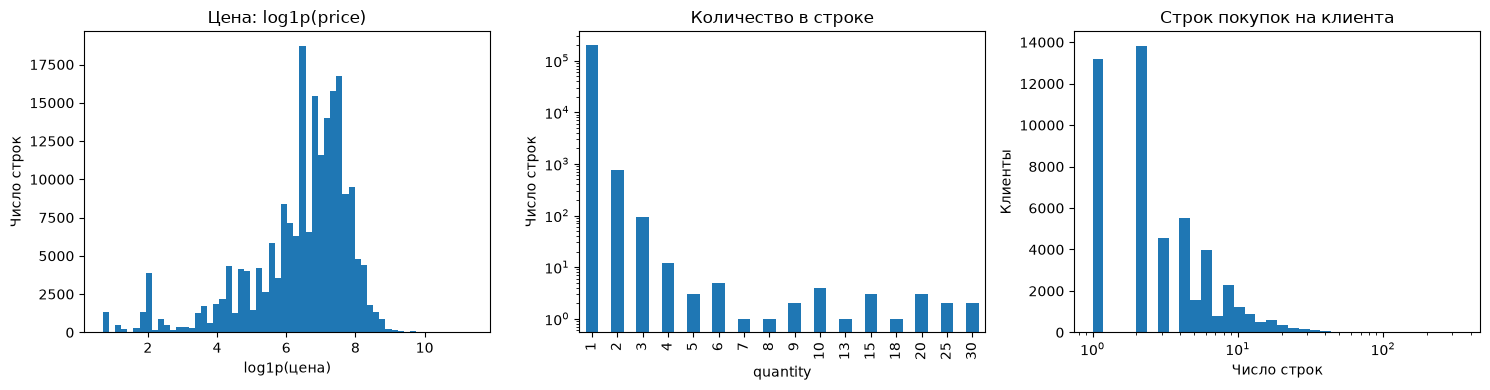

Клиентов с одной строкой: 26.5%; с одним днём покупок: 85.7%


In [4]:
# Проверка таргета и качества покупок
assert target["client_id"].is_unique
assert target["target"].isin([0, 1]).all()
assert target.notna().all().all()

display(purchases.isna().sum().rename("Пропуски").to_frame())
purchase_duplicates = int(purchases.duplicated().sum())
print(
    f"Полных совпадений строк покупок: {purchase_duplicates:,} "
    f"({purchase_duplicates / len(purchases):.1%})"
)
display(purchases[["price", "quantity"]].describe(percentiles=[0.01, 0.5, 0.99, 0.999]))

required_columns = ["client_id", "date", "price", "quantity"]
invalid = (
    purchases["price"].le(0) | purchases["quantity"].le(0)
    | purchases[required_columns].isna().any(axis=1)
)
print("Некорректных строк:", invalid.sum())
assert not invalid.any(), "Нужно уточнить и обработать некорректные покупки"

print("Строк с ценой < 10:", purchases["price"].lt(10).sum())
print("Строк с количеством > 1:", purchases["quantity"].gt(1).sum())

# Активность клиентов и распределения
rows_per_client = purchases.groupby("client_id").size()
days_per_client = purchases.groupby("client_id")["date"].nunique()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(np.log1p(purchases["price"]), bins=60)
axes[0].set(title="Цена: log1p(price)", xlabel="log1p(цена)", ylabel="Число строк")

purchases["quantity"].value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set(
    title="Количество в строке", xlabel="quantity",
    ylabel="Число строк", yscale="log",
)

axes[2].hist(rows_per_client, bins=np.geomspace(1, rows_per_client.max() + 1, 35))
axes[2].set(
    title="Строк покупок на клиента", xlabel="Число строк",
    ylabel="Клиенты", xscale="log",
)
plt.tight_layout()
plt.show()

print(
    f"Клиентов с одной строкой: {rows_per_client.eq(1).mean():.1%}; "
    f"с одним днём покупок: {days_per_client.eq(1).mean():.1%}"
)

**Вывод по покупкам.** В таблице нет идентификаторов заказа и товара: совпадение всех шести
полей может означать как повтор выгрузки, так и несколько одинаковых позиций в одном заказе.
Без подтверждения источника не удаляем 73 020 совпадений (36,1% строк), чтобы не потерять
реальные продажи. Поэтому частотные признаки называем **числом строк**, а число различных
дней покупок используем отдельно; число заказов по этим данным определить нельзя.
При внедрении нужно запросить `order_id`, `product_id` и проверить чувствительность к дедупликации.

Цена имеет тяжёлый правый хвост; положительные цены 1–9 требуют уточнения единиц и механики
скидок, но сами по себе не доказывают ошибку. Их и дорогие товары сохраняем: произвольный порог
удаления исказил бы поведение клиентов. Для линейной модели сравним исходные признаки
с `log1p` на train CV. Интервал между покупками определяем по разным дням: при одном дне
интервал неизвестен, поэтому оставляем `NaN`, а не ноль. Печать долей выше показывает масштаб
этой группы.

### 2.2. Полный обзор рассылок

Период рассылок: 2022-05-19 00:00:00 — 2024-02-15 00:00:00
Строк: 12,739,798; полных дубликатов: 48,610
Клиентов таргета без рассылок: 7,867 (15.78%)


,Пропуски
bulk_campaign_id,0
client_id,0
message_id,0
event,0
channel,0
date,0
created_at,0


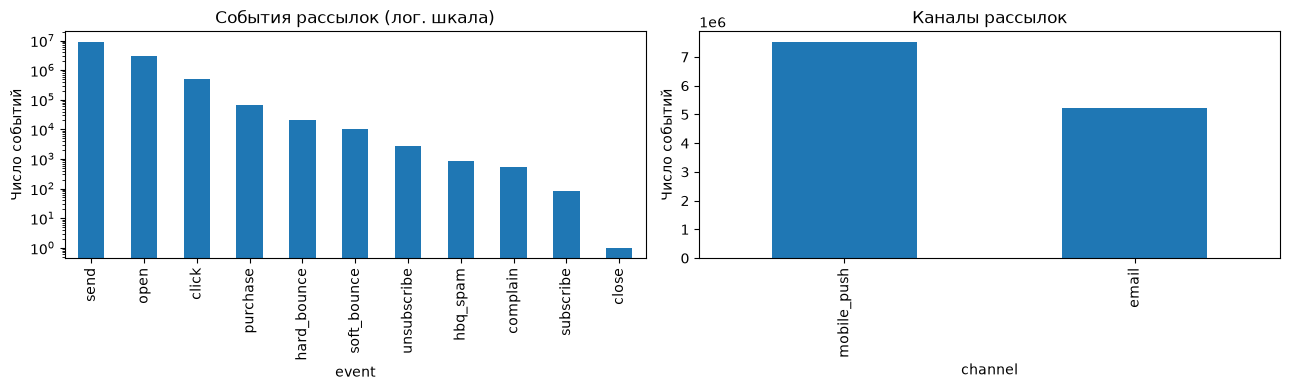

,Доля событий
event,
send,7.110157e-01
open,2.422189e-01
click,3.895972e-02
purchase,5.076925e-03
hard_bounce,1.562270e-03
soft_bounce,8.307039e-04
unsubscribe,2.230020e-04
hbq_spam,6.460071e-05
complain,4.144493e-05


,Доля канала
channel,
mobile_push,0.589661
email,0.410339


In [5]:
# Обзор рассылок чанками: статистика и поиск кандидатов на дубликаты
message_path = DATA_DIR / "apparel-messages.csv"
read_params = dict(
    dtype={"client_id": str, "bulk_campaign_id": str},
    parse_dates=["date"], chunksize=500_000,
)

event_counts, channel_counts, hashes = [], [], []
message_clients = set()
message_min, message_max, message_missing = None, None, None
message_rows = 0

for chunk in pd.read_csv(message_path, **read_params):
    message_rows += len(chunk)
    chunk_missing = chunk.isna().sum()
    message_missing = (
        chunk_missing if message_missing is None
        else message_missing.add(chunk_missing, fill_value=0)
    )
    event_counts.append(chunk["event"].value_counts(dropna=False))
    channel_counts.append(chunk["channel"].value_counts(dropna=False))
    message_clients.update(chunk["client_id"].dropna())

    lo, hi = chunk["date"].min(), chunk["date"].max()
    message_min = lo if message_min is None else min(message_min, lo)
    message_max = hi if message_max is None else max(message_max, hi)
    hashes.append(pd.util.hash_pandas_object(chunk, index=False).to_numpy())

all_hashes = np.concatenate(hashes)
unique_hashes, hash_counts = np.unique(all_hashes, return_counts=True)
duplicate_hashes = unique_hashes[hash_counts > 1]
del hashes, all_hashes, unique_hashes, hash_counts

# Точное сравнение строк-кандидатов, включая совпадения между чанками
message_duplicates = 0
if len(duplicate_hashes):
    candidates = []
    for chunk in pd.read_csv(message_path, **read_params):
        chunk_hashes = pd.util.hash_pandas_object(chunk, index=False).to_numpy()
        mask = np.isin(chunk_hashes, duplicate_hashes)
        if mask.any():
            candidates.append(chunk.loc[mask])

    message_duplicates = int(pd.concat(candidates, ignore_index=True).duplicated().sum())
    del candidates
del duplicate_hashes

# Объединение статистики
event_counts = (
    pd.concat(event_counts, axis=1).fillna(0)
    .sum(axis=1).sort_values(ascending=False)
)
channel_counts = (
    pd.concat(channel_counts, axis=1).fillna(0)
    .sum(axis=1).sort_values(ascending=False)
)
no_messages = ~target["client_id"].isin(message_clients)

print("Период рассылок:", message_min, "—", message_max)
print(f"Строк: {message_rows:,}; полных дубликатов: {message_duplicates:,}")
print(
    f"Клиентов таргета без рассылок: {no_messages.sum():,} "
    f"({no_messages.mean():.2%})"
)
display(message_missing.rename("Пропуски").to_frame())

# Распределения событий и каналов
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
event_counts.plot.bar(ax=axes[0], logy=True, title="События рассылок (лог. шкала)")
channel_counts.plot.bar(ax=axes[1], title="Каналы рассылок")
for ax in axes:
    ax.set_ylabel("Число событий")
plt.tight_layout()
plt.show()

display((event_counts / message_rows).rename("Доля событий").to_frame())
display((channel_counts / message_rows).rename("Доля канала").to_frame())

assert message_missing[["client_id", "date", "event", "channel"]].eq(0).all()

In [6]:
display(Markdown(
    f"**Вывод по рассылкам.** Проверена вся таблица, включая совпадения между чанками. "
    f"Полных дубликатов: **{message_duplicates:,}**. "
    f"Самое частое событие — `{event_counts.index[0]}`, "
    f"основной канал — `{channel_counts.index[0]}`. "
    f"У **{no_messages.mean():.2%}** клиентов таргета нет рассылок: "
    "счётчики для них будут нулевыми, давность неизвестна. "
    "Счётчики описывают регистрации событий, а не уникальные сообщения: "
    "повторное открытие одного message_id допустимо. "
    "Полные совпадения, если они встретились, сохраняем до уточнения семантики журнала; "
    "не объединяем разные события одного сообщения в одну строку."))

**Вывод по рассылкам.** Проверена вся таблица, включая совпадения между чанками. Полных дубликатов: **48,610**. Самое частое событие — `send`, основной канал — `mobile_push`. У **15.78%** клиентов таргета нет рассылок: счётчики для них будут нулевыми, давность неизвестна. Счётчики описывают регистрации событий, а не уникальные сообщения: повторное открытие одного message_id допустимо. Полные совпадения, если они встретились, сохраняем до уточнения семантики журнала; не объединяем разные события одного сообщения в одну строку.

### 2.3. Агрегаты кампаний

In [7]:
campaign_summaries = []
for name in ["full_campaign_daily_event.csv", "full_campaign_daily_event_channel.csv"]:
    campaign = pd.read_csv(DATA_DIR / name, dtype={"bulk_campaign_id": str}, parse_dates=["date"])
    campaign_summaries.append({
        "Таблица": name, "Строк": len(campaign), "Колонок": campaign.shape[1],
        "Начало": campaign["date"].min(), "Конец": campaign["date"].max(),
        "Пропуски": int(campaign.isna().sum().sum()),
        "Полные дубликаты": int(campaign.duplicated().sum()),
        "Дубли дата/кампания": int(campaign.duplicated(["date", "bulk_campaign_id"]).sum()),
        "Строк после истории покупок": int(campaign["date"].gt(purchases["date"].max()).sum()),
    })
    display(campaign.head(3))
    numeric = campaign.select_dtypes("number")
    assert numeric.ge(0).all().all()
    print("Суммы счётчиков:")
    display(numeric.sum().to_frame("Сумма"))
display(pd.DataFrame(campaign_summaries).set_index("Таблица"))

,date,bulk_campaign_id,count_click,count_complain,count_hard_bounce,count_open,count_purchase,count_send,count_soft_bounce,count_subscribe,count_unsubscribe,nunique_click,nunique_complain,nunique_hard_bounce,nunique_open,nunique_purchase,nunique_send,nunique_soft_bounce,nunique_subscribe,nunique_unsubscribe,count_hbq_spam,nunique_hbq_spam,count_close,nunique_close
0,2022-05-19,563,0,0,0,4,0,0,0,0,0,0,0,0,4,0,0,0,0,0,0,0,0,0
1,2022-05-19,577,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
2,2022-05-19,622,0,0,0,2,0,0,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0


Суммы счётчиков:


,Сумма
count_click,11925320
count_complain,122245
count_hard_bounce,10285670
count_open,494284399
count_purchase,75750
count_send,1524910302
count_soft_bounce,3644760
count_subscribe,18418
count_unsubscribe,833969
nunique_click,9735506


,date,bulk_campaign_id,count_click_email,count_click_mobile_push,count_open_email,count_open_mobile_push,count_purchase_email,count_purchase_mobile_push,count_soft_bounce_email,count_subscribe_email,count_unsubscribe_email,nunique_click_email,nunique_click_mobile_push,nunique_open_email,nunique_open_mobile_push,nunique_purchase_email,nunique_purchase_mobile_push,nunique_soft_bounce_email,nunique_subscribe_email,nunique_unsubscribe_email,count_hard_bounce_mobile_push,count_send_mobile_push,nunique_hard_bounce_mobile_push,nunique_send_mobile_push,count_hard_bounce_email,count_hbq_spam_email,count_send_email,nunique_hard_bounce_email,nunique_hbq_spam_email,nunique_send_email,count_soft_bounce_mobile_push,nunique_soft_bounce_mobile_push,count_complain_email,nunique_complain_email,count_close_mobile_push,nunique_close_mobile_push
0,2022-05-19,563,0,0,4,0,0,0,0,0,0,0,0,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2022-05-19,577,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,2022-05-19,622,0,0,2,0,0,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Суммы счётчиков:


,Сумма
count_click_email,5450258
count_click_mobile_push,6475062
count_open_email,55535997
count_open_mobile_push,438748402
count_purchase_email,46856
count_purchase_mobile_push,28894
count_soft_bounce_email,3207964
count_subscribe_email,18418
count_unsubscribe_email,833969
nunique_click_email,4115171


,Строк,Колонок,Начало,Конец,Пропуски,Полные дубликаты,Дубли дата/кампания,Строк после истории покупок
Таблица,,,,,,,,
full_campaign_daily_event.csv,131072,24,2022-05-19,2024-05-15,0,0,0,21317
full_campaign_daily_event_channel.csv,131072,36,2022-05-19,2024-05-15,0,0,0,21317


**Вывод по агрегатам кампаний.** Обе таблицы содержат 131 072 строки, ключ
`date + bulk_campaign_id` уникален, пропусков и полных дубликатов нет. Одна таблица содержит
счётчики событий и уникальных клиентов, другая — их детализацию по каналам. `client_id` в них
нет: это характеристики кампании и дня, а не отдельного покупателя.

**Критичный результат EDA:** агрегаты заканчиваются **2024-05-15**, позже истории покупок
и рассылок. Использование полных итогов кампаний внесло бы информацию из будущего.
В текущую модель эти таблицы не включаем. Для расширения нужно сначала ограничить их
точкой среза, затем связать с клиентами через кампании из журнала рассылок; число строк
после границы показано выше. Эти агрегаты не используются для выбора точки среза.

## 3. Временная граница и защита от утечки

EDA показал: покупки заканчиваются **2024-02-16**, рассылки — **2024-02-15**.
Предположение версии v1 о совпадении дат не подтвердилось. За общий срез берём максимум
окончаний клиентских историй — **2024-02-16**. Не сдвигаем его на день назад только ради
совпадения источников: это изменило бы соответствие признаков предоставленному таргету.
Давность рассылок считаем от общего среза, поэтому её минимум — один день. Последний день
рассылок неизвестен: отсутствие события означает отсутствие в **доступной** истории.
Проверки контролируют, что конец покупок совпадает со срезом, а отставание рассылок не выросло
относительно обнаруженного однодневного разрыва. Для внедрения нужно подтвердить полноту источника.

Целевое окно следующих 90 дней задано постановкой. Подтвердить процедуру расчёта таргета
по этим историям нельзя; нужно согласовать с владельцем данных точку его формирования.
Агрегаты кампаний содержат более поздние даты и в признаки не входят. Все функции явно
отсекают будущее. Дата среза включается целиком, поскольку `date` имеет дневную точность.

In [8]:
# Общая точка среза и разрыв покрытия рассылок
purchase_end = purchases["date"].max().normalize()
message_end = message_max.normalize()
SNAPSHOT = max(purchase_end, message_end)
message_coverage_gap_days = (SNAPSHOT - message_end).days

print("Конец покупок:", purchase_end, "| конец рассылок:", message_end)
print("Snapshot:", SNAPSHOT.date(), "| разрыв покрытия, дней:", message_coverage_gap_days)

assert purchase_end == SNAPSHOT, "Рассылки выходят за границу покупок: проверьте дату таргета"
assert 0 <= message_coverage_gap_days <= 1, "Разрыв покрытия вырос: согласуйте данные"

if purchase_end != message_end:
    print(
        "Последний день рассылок отсутствует. Давность считаем от общего среза; "
        "отсутствие события в доступной истории не доказывает бездействие."
    )

Конец покупок: 2024-02-16 00:00:00 | конец рассылок: 2024-02-15 00:00:00
Snapshot: 2024-02-16 | разрыв покрытия, дней: 1
Последний день рассылок отсутствует. Давность считаем от общего среза; отсутствие события в доступной истории не доказывает бездействие.


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Рассуждение про временную границу верное и хорошо изложено: целевая метка посчитана вне предоставленных таблиц, поэтому точка среза — последняя доступная дата, а все признаки строятся строго по истории до неё. Многие на этом шаге путаются, у тебя логика прозрачная.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Две мысли:

1. `SNAPSHOT` задан вручную, а утверждение «история рассылок заканчивается 2024-02-16» в коде нигде не проверено. Надёжнее вычислить дату из данных (максимум по обеим таблицам) и добавить `assert`, что таблицы заканчиваются одновременно — если рассылки обрываются раньше, признаки давности по ним будут смещены.
2. Как альтернативу (по желанию) можно построить «исторический» срез: взять точку на 90 дней раньше, посчитать признаки до неё, а таргет — по факту покупок в следующие 90 дней из самих данных. Это позволит проверить, насколько модель устойчива во времени, а заодно даёт дополнительную обучающую выборку. Хороший задел для раздела «Возможные улучшения».
</div>

<div class="alert alert-info">
<b>Комментарий студента — отработка замечания v1</b><br>
Дата вычисляется по окончаниям двух клиентских историй. EDA опроверг совпадение: покупки до 16.02, рассылки до 15.02. Срез 16.02 сохранён, однодневный разрыв покрытия выведен и проверяется assert; давность считается от общего среза. Неизвестный день рассылок отмечен как ограничение. В функциях признаки ограничены включительно датой среза. Более поздние агрегаты кампаний не определяют snapshot. Исторические срезы добавлены в план развития.
</div>

## 4. Признаки по покупкам (RFM и производные)

Считаем классические RFM-показатели и их расширения: давность последней покупки (recency),
частоту (frequency), сумму (monetary), активность в скользящих окнах 30/90/180/365 дней,
средний интервал между покупками и признак тренда (покупки в последние 90 дней против
предыдущих 90).

In [9]:
def build_purchase_features(pur, snapshot):
    pur = pur.loc[pur["date"] < snapshot.normalize() + pd.Timedelta(days=1)].copy()
    pur["amount"] = pur["price"] * pur["quantity"]
    g = pur.groupby("client_id")
    f = pd.DataFrame(index=g.size().index)
    f["p_n_rows"] = g.size()  # строки товарных позиций, не число заказов
    f["p_n_days"] = g["date"].nunique()
    f["p_total_qty"] = g["quantity"].sum()
    f["p_total_spend"] = g["amount"].sum()
    f["p_avg_price"] = g["price"].mean()
    f["p_max_price"] = g["price"].max()
    f["p_min_price"] = g["price"].min()
    f["p_avg_amount"] = g["amount"].mean()
    last, first = g["date"].max(), g["date"].min()
    f["p_recency_days"] = (snapshot - last).dt.days
    f["p_tenure_days"] = (snapshot - first).dt.days
    f["p_span_days"] = (last - first).dt.days
    f["p_avg_interpurchase"] = f["p_span_days"] / (f["p_n_days"] - 1).replace(0, np.nan)
    for w in (30, 90, 180, 365):
        sub = pur[pur["date"] > snapshot - pd.Timedelta(days=w)]
        f[f"p_rows_last_{w}"] = sub.groupby("client_id").size().reindex(f.index, fill_value=0)
        f[f"p_spend_last_{w}"] = sub.groupby("client_id")["amount"].sum().reindex(f.index, fill_value=0)
    prev = pur[(pur["date"] <= snapshot - pd.Timedelta(days=90)) &
               (pur["date"] > snapshot - pd.Timedelta(days=180))]
    f["p_rows_prev_90"] = prev.groupby("client_id").size().reindex(f.index, fill_value=0)
    f["p_rows_ratio_90"] = f["p_rows_last_90"] / f["p_rows_prev_90"].replace(0, np.nan)
    f["p_has_prev_90"] = f["p_rows_prev_90"].gt(0).astype(int)
    f["p_repeat_buyer"] = f["p_n_days"].gt(1).astype(int)
    return f

### Обработка `category_ids`

Первый элемент используем только как технический группировочный код, а не как подтверждённый
пол, распродажу или уровень дерева: словаря категорий нет. Число различных id учитывает все
элементы списка. Пять частых начальных кодов выбираем **по клиентам обучающей выборки**,
до просмотра теста; выводим частоты. Числа строк и доли по выбранным кодам дополняют RFM.
Смена иерархии может изменить смысл начального кода, поэтому этот набор требует мониторинга.

In [10]:
def parse_cat(s):
    try:
        value = ast.literal_eval(s)
        return [str(x) for x in value] if isinstance(value, list) else []
    except (ValueError, SyntaxError, TypeError):
        return []


# Выбираем категории только по train
train_clients, test_clients = train_test_split(
    target["client_id"], test_size=0.2,
    stratify=target["target"], random_state=RANDOM_STATE,
)

parsed_cats = purchases["category_ids"].map(parse_cat)
print("Пустые или неразобранные списки категорий:", parsed_cats.map(len).eq(0).sum())

first_cats = parsed_cats.map(lambda values: values[0] if values else None)
category_counts = first_cats[purchases["client_id"].isin(train_clients)].value_counts()
display(category_counts.head(15).rename("Число строк train").to_frame())
TOP_CATEGORIES = category_counts.head(5).index.tolist()


def build_category_features(pur, snapshot):
    pur = pur.loc[pur["date"] < snapshot.normalize() + pd.Timedelta(days=1)].copy()
    pur["cats"] = pur["category_ids"].map(parse_cat)
    f = pd.DataFrame(index=pd.Index(pur["client_id"].unique(), name="client_id"))

    exploded = pur[["client_id", "cats"]].explode("cats")
    f["p_n_distinct_cat"] = exploded.groupby("client_id")["cats"].nunique()
    pur["top"] = pur["cats"].map(lambda values: values[0] if values else None)
    total = pur.groupby("client_id").size()

    for category in TOP_CATEGORIES:
        col = f"p_cat_{category}"
        f[col] = (
            pur[pur["top"] == category].groupby("client_id")
            .size().reindex(f.index, fill_value=0)
        )
        f[col + "_share"] = f[col] / total

    return f

Пустые или неразобранные списки категорий: 5579


,Число строк train
category_ids,
4,90521
5562,36853
2,21856
6060,6003
5963,1027
None,1024
3,11
1,2
5,2


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Очень сильный блок признаков. Помимо классического RFM есть скользящие окна 30/90/180/365, тренд (последние 90 дней против предыдущих 90), срок жизни клиента, «размах» истории и средний интервал между покупками. Функция параметризована точкой среза — её можно без изменений переиспользовать в проде, о чём ты потом и пишешь в выводах. Подход к `category_ids` продуманный: не опираться на позицию в списке, раз дерево категорий меняет глубину, — это зрелое решение, а `parse_cat` с `try/except` защищает от битых строк.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> - У клиентов с одной покупкой `p_avg_interpurchase` после `fillna(0)` становится равным 0, что для модели выглядит как «покупает каждый день» — смысл ровно противоположный. `HistGradientBoostingClassifier` умеет работать с `NaN` нативно, так что для бустинга пропуск лучше оставить пропуском (или добавить отдельный флаг, как ты сделал(а) с `p_repeat_buyer`).
- Список `TOP_CATEGORIES` захардкожен, а расчёт частот, по которому он получен, в тетрадке отсутствует. Добавь ячейку с `value_counts`, чтобы выбор был воспроизводим.
- Идея на попробовать: доли покупок по категориям вместо абсолютных чисел (абсолютные сильно коррелируют с `p_n_tx`) и явное отношение `p_tx_last_90 / p_tx_prev_90`.
</div>

<div class="alert alert-info">
<b>Комментарий автора — отработка замечания v1</b><br>
Неизвестный межпокупочный интервал оставлен NaN; есть признак повторной покупки по дням. TOP_CATEGORIES вычисляется по частотам на train и выводится таблицей. Добавлены доли категорий, отношение активности последних двух 90-дневных окон и индикатор наличия активности в предыдущем окне. Число строк больше не называется числом транзакций.
</div>

## 5. Признаки по рассылкам

Из истории рассылок извлекаем поведение клиента: сколько сообщений отправлено/открыто/кликнуто,
open-rate и click-rate, давность последнего события / открытия / клика, активность за 90 дней,
доля email против push, флаги отписки/жалоб/возвратов. Файл читаем чанками и агрегируем
векторно.

In [11]:
EVENTS = ["send", "open", "click", "purchase", "unsubscribe",
          "hard_bounce", "soft_bounce", "complain", "subscribe", "hbq_spam", "close"]

def build_message_features(path, snapshot, chunksize=500_000):
    cut90 = snapshot - pd.Timedelta(days=90)
    counts, chan, win, last = [], [], [], []

    reader = pd.read_csv(path, usecols=["client_id", "event", "channel", "date"],
                         dtype={"client_id": str}, parse_dates=["date"],
                         chunksize=chunksize)
    for chunk in reader:
        unknown = set(chunk["event"].dropna()) - set(EVENTS)
        if unknown:
            raise ValueError(f"Неизвестные события: {unknown}")
        chunk = chunk[chunk["date"] < snapshot.normalize() + pd.Timedelta(days=1)]
        counts.append(chunk.groupby(["client_id", "event"]).size())
        chan.append(chunk.groupby(["client_id", "channel"]).size())
        c90 = chunk[chunk["date"] > cut90]
        win.append(c90[c90["event"].isin(["send", "open", "click"])]
                   .groupby(["client_id", "event"]).size())
        last.append(pd.DataFrame({
            "m_last": chunk.groupby("client_id")["date"].max(),
            "m_last_open": chunk[chunk["event"] == "open"].groupby("client_id")["date"].max(),
            "m_last_click": chunk[chunk["event"] == "click"].groupby("client_id")["date"].max(),
        }))

    ev_cnt = pd.concat(counts).groupby(level=[0, 1]).sum().unstack(fill_value=0)
    ev_cnt.columns = [f"m_{c}" for c in ev_cnt.columns]
    ch_cnt = pd.concat(chan).groupby(level=[0, 1]).sum().unstack(fill_value=0)
    ch_cnt = ch_cnt.rename(columns={"email": "m_email", "mobile_push": "m_push"})
    w_cnt = pd.concat(win).groupby(level=[0, 1]).sum().unstack(fill_value=0)
    w_cnt.columns = [f"m_{c}_90" for c in w_cnt.columns]
    last_df = pd.concat(last).groupby(level=0).max()

    m = ev_cnt.join(ch_cnt, how="outer").join(w_cnt, how="outer").join(last_df, how="outer")
    for col in [f"m_{e}" for e in EVENTS] + ["m_email", "m_push",
                                             "m_send_90", "m_open_90", "m_click_90"]:
        if col not in m:
            m[col] = 0
    keep_dates = ["m_last", "m_last_open", "m_last_click"]
    m = m.fillna({c: 0 for c in m.columns if c not in keep_dates})
    m.index.name = "client_id"

    m["m_last_msg_days"] = (snapshot - m["m_last"]).dt.days
    m["m_last_open_days"] = (snapshot - m["m_last_open"]).dt.days
    m["m_last_click_days"] = (snapshot - m["m_last_click"]).dt.days
    m = m.drop(columns=keep_dates)

    denom = m["m_send"].replace(0, np.nan)
    m["m_open_rate"] = (m["m_open"] / denom).fillna(0)
    m["m_click_rate"] = (m["m_click"] / denom).fillna(0)
    m["m_ctr_open"] = (m["m_click"] / m["m_open"].replace(0, np.nan)).fillna(0)
    m["m_share_email"] = (m["m_email"] /
                          (m["m_email"] + m["m_push"]).replace(0, np.nan)).fillna(0)
    m["m_total"] = m[[f"m_{e}" for e in EVENTS]].sum(axis=1)
    for c in ["m_last_msg_days", "m_last_open_days", "m_last_click_days"]:
        m[c + "_observed"] = m[c].notna().astype(int)
    return m

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Инженерно очень грамотно: чтение 1.4 ГБ чанками только нужных колонок, агрегация векторно, частичные результаты корректно объединяются — счётчики суммируются, а даты последних событий берутся как максимум по чанкам. Open-rate, click-rate и CTR от открытий с защитой от деления на ноль — хороший набор поведенческих признаков, а разделение каналов email/push добавляет полезный контекст.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Значение 9999 для «события не было» нормально работает в деревьях, но в логистической регрессии после `StandardScaler` такие значения превращаются в огромные выбросы и заметно искажают коэффициенты (а логрегрессия потом входит в твой финальный ансамбль). Варианты: бинарный флаг «событие было» + ограничение давности сверху разумной величиной (например, сроком жизни клиента), либо логарифм. Для бустинга можно оставить `NaN`.
</div>

<div class="alert alert-info">
<b>Комментарий студента — отработка замечания v1</b><br>
Значения 9999 удалены. Давность без события остаётся NaN; добавлены индикаторы наблюдения события. HGB получает NaN напрямую; логрегрессия использует медианную импутацию с индикаторами внутри pipeline. Вариант log1p сравнивается с исходным на одинаковых CV фолдах.
</div>

## 6. Сборка обучающей таблицы

Соединяем признаки с таргетом по `client_id` с проверкой отношения один к одному.
Перед заполнением выводим пропуски. Нули ставим только по счётчикам и индикаторам.
Неизвестные интервалы, давность и неопределённое отношение сохраняем как `NaN`:
бустинг обрабатывает их напрямую, а линейная модель использует импутацию внутри CV.

In [12]:
# Построение и объединение признаков
pf = build_purchase_features(purchases, SNAPSHOT)
cf = build_category_features(purchases, SNAPSHOT)
mf = build_message_features(DATA_DIR / "apparel-messages.csv", SNAPSHOT)

data = (
    target.merge(pf, on="client_id", how="left", validate="one_to_one")
    .merge(cf.reset_index(), on="client_id", how="left", validate="one_to_one")
    .merge(mf.reset_index(), on="client_id", how="left", validate="one_to_one")
)
assert data["client_id"].is_unique and len(data) == len(target)

display(
    data.isna().sum().loc[lambda s: s.gt(0)]
    .rename("Пропуски до обработки").to_frame()
)

# Сохраняем неизвестные интервалы и давность; счётчики заполняем нулями
nullable = [
    "p_avg_interpurchase", "p_rows_ratio_90",
    "m_last_msg_days", "m_last_open_days", "m_last_click_days",
]
zero_cols = [c for c in data.columns if c.startswith("m_") and c not in nullable]
data[zero_cols] = data[zero_cols].fillna(0)

assert not data.drop(columns=nullable).isna().any().any(), "Неожиданные пропуски"
assert not np.isinf(data.drop(columns="client_id").to_numpy(dtype=float)).any()

print("Обучающая таблица:", data.shape)
print("Доля целевого класса:", round(data["target"].mean(), 4))
data.head()

,Пропуски до обработки
p_avg_interpurchase,42706
p_rows_ratio_90,46392
m_click,7867
m_close,7867
m_complain,7867
m_hard_bounce,7867
m_hbq_spam,7867
m_open,7867
m_purchase,7867
m_send,7867


Обучающая таблица: (49849, 64)
Доля целевого класса: 0.0193


,client_id,target,p_n_rows,p_n_days,p_total_qty,p_total_spend,p_avg_price,p_max_price,p_min_price,p_avg_amount,p_recency_days,p_tenure_days,p_span_days,p_avg_interpurchase,p_rows_last_30,p_spend_last_30,p_rows_last_90,p_spend_last_90,p_rows_last_180,p_spend_last_180,p_rows_last_365,p_spend_last_365,p_rows_prev_90,p_rows_ratio_90,p_has_prev_90,p_repeat_buyer,p_n_distinct_cat,p_cat_4,p_cat_4_share,p_cat_5562,p_cat_5562_share,p_cat_2,p_cat_2_share,p_cat_6060,p_cat_6060_share,p_cat_5963,p_cat_5963_share,m_click,m_close,m_complain,m_hard_bounce,m_hbq_spam,m_open,m_purchase,m_send,m_soft_bounce,m_subscribe,m_unsubscribe,m_email,m_push,m_click_90,m_open_90,m_send_90,m_last_msg_days,m_last_open_days,m_last_click_days,m_open_rate,m_click_rate,m_ctr_open,m_share_email,m_total,m_last_msg_days_observed,m_last_open_days_observed,m_last_click_days_observed
0,1515915625468060902,0,7,1,7,6993.0,999.000000,1999.0,199.0,999.000000,630,630,0,NaN,0,0.0,0,0.0,0,0.0,0,0.0,0,NaN,0,0,13,7,1.000000,0,0.0,0,0.000000,0,0.0,0,0.0,10.0,0.0,0.0,0.0,0.0,35.0,5.0,126.0,0.0,0.0,1.0,177.0,0.0,2.0,6.0,19.0,28.0,28.0,41.0,0.277778,0.079365,0.285714,1.00000,177.0,1.0,1.0,1.0
1,1515915625468061003,1,7,1,7,16235.0,2319.285714,3499.0,1749.0,2319.285714,408,408,0,NaN,0,0.0,0,0.0,0,0.0,0,0.0,0,NaN,0,0,4,7,1.000000,0,0.0,0,0.000000,0,0.0,0,0.0,6.0,0.0,0.0,0.0,0.0,5.0,1.0,154.0,0.0,0.0,0.0,166.0,0.0,1.0,1.0,16.0,3.0,87.0,87.0,0.032468,0.038961,1.200000,1.00000,166.0,1.0,1.0,1.0
2,1515915625468061099,0,1,1,1,299.0,299.000000,299.0,299.0,299.000000,640,640,0,NaN,0,0.0,0,0.0,0,0.0,0,0.0,0,NaN,0,0,4,1,1.000000,0,0.0,0,0.000000,0,0.0,0,0.0,8.0,0.0,0.0,2.0,0.0,51.0,0.0,215.0,0.0,0.0,0.0,182.0,94.0,0.0,1.0,28.0,3.0,24.0,172.0,0.237209,0.037209,0.156863,0.65942,276.0,1.0,1.0,1.0
3,1515915625468061100,0,2,1,2,2098.0,1049.000000,1049.0,1049.0,1049.000000,6,6,0,NaN,2,2098.0,2,2098.0,2,2098.0,2,2098.0,0,NaN,0,0,4,2,1.000000,0,0.0,0,0.000000,0,0.0,0,0.0,1.0,0.0,0.0,1.0,0.0,163.0,1.0,267.0,1.0,0.0,0.0,0.0,434.0,1.0,60.0,68.0,1.0,1.0,7.0,0.610487,0.003745,0.006135,0.00000,434.0,1.0,1.0,1.0
4,1515915625468061170,0,19,3,19,33601.0,1768.473684,2699.0,7.0,1768.473684,244,327,83,41.5,0,0.0,0,0.0,0,0.0,19,33601.0,0,NaN,0,1,10,15,0.789474,0,0.0,2,0.105263,0,0.0,0,0.0,16.0,0.0,0.0,0.0,0.0,31.0,3.0,243.0,0.0,0.0,0.0,202.0,91.0,0.0,6.0,108.0,1.0,71.0,118.0,0.127572,0.065844,0.516129,0.68942,293.0,1.0,1.0,1.0


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Сборка через `left join` от таблицы таргета гарантирует, что каждый клиент из выборки попадёт в данные ровно один раз, а печать размера и доли целевого класса после объединения — правильная привычка: сразу видно, что строки не размножились и не потерялись.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Полезно закрепить это проверкой в коде: `assert data["client_id"].is_unique and len(data) == len(target)`. И отдельно — общий `data.fillna(0)` в конце может «молча» заполнить пропуски, о которых ты не знаешь; перед ним стоит вывести, в каких колонках они вообще были.
</div>

<div class="alert alert-info">
<b>Комментарий студента — отработка замечания v1</b><br>
Добавлены validate="one_to_one", assert уникальности client_id и сохранения числа строк. Пропуски выводятся до обработки; заполнение нулями ограничено счётчиками рассылок. Неожиданные пропуски приводят к ошибке.
</div>

## 7. Разбиение на train/test

Отложенная выборка 20% со стратификацией по таргету (важно при дисбалансе).

In [13]:
indexed = data.set_index("client_id")
X = indexed.drop(columns="target")
y = indexed["target"]
X_tr, X_te = X.loc[train_clients], X.loc[test_clients]
y_tr, y_te = y.loc[train_clients], y.loc[test_clients]
assert X_tr.index.intersection(X_te.index).empty
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
print("train:", X_tr.shape, "| test:", X_te.shape)

train: (39879, 62) | test: (9970, 62)


## 8. Базовые модели и кросс-валидация

Сравним логистическую регрессию (линейный бейзлайн, признаки масштабируем) и градиентный
бустинг `HistGradientBoostingClassifier`. Метрика — ROC-AUC по 5-фолдовой стратифицированной
кросс-валидации на train.

In [14]:
def make_logreg(log_transform=False):
    steps = []
    if log_transform:
        steps.append(FunctionTransformer(np.log1p, feature_names_out="one-to-one"))
    steps.extend([SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                  LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)])
    return make_pipeline(*steps)

baseline_scores = {}
for name, model in [("LogReg", make_logreg()), ("LogReg log1p", make_logreg(True)),
                    ("HGB default", HistGradientBoostingClassifier(
                        random_state=RANDOM_STATE, class_weight="balanced", early_stopping=True))]:
    scores = cross_val_score(model, X_tr, y_tr, cv=cv, scoring="roc_auc", n_jobs=N_JOBS)
    baseline_scores[name] = scores
    print(f"{name}: CV ROC-AUC {scores.mean():.4f} +/- {scores.std():.4f}")
lr_name = max(["LogReg", "LogReg log1p"], key=lambda name: baseline_scores[name].mean())
logreg = make_logreg(lr_name == "LogReg log1p")
print("Вариант логрегрессии по train CV:", lr_name)

LogReg: CV ROC-AUC 0.7567 +/- 0.0167
LogReg log1p: CV ROC-AUC 0.7648 +/- 0.0170
HGB default: CV ROC-AUC 0.7493 +/- 0.0163
Вариант логрегрессии по train CV: LogReg log1p


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Схема валидации правильная: стратифицированная отложенная выборка, кросс-валидация только на train, тест не трогается до финала. Бейзлайны разной природы — линейная модель и бустинг — хороший выбор, и наблюдение, что логрегрессия «из коробки» не уступает бустингу, само по себе информативно: зависимости в данных в основном монотонные.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Логрегрессии заметно помогло бы логарифмирование (`np.log1p`) признаков с тяжёлыми хвостами — сумм, числа отправок, числа транзакций. `StandardScaler` меняет масштаб, но не форму распределения, и несколько крупных клиентов «тянут» коэффициенты на себя. Попробуй — вполне может добавить пару сотых к ROC-AUC.
</div>

<div class="alert alert-info">
<b>Комментарий студента — отработка замечания v1</b><br>
Добавлен вариант логрегрессии с log1p до импутации и масштабирования. Преобразования обучаются внутри CV. Выбор варианта делается по среднему ROC-AUC на train, результаты выводятся рядом.
</div>

## 9. Тюнинг градиентного бустинга

Проверяем гипотезу о пользе неглубоких деревьев и регуляризации при редком положительном
классе. Гиперпараметры выбираем по среднему ROC-AUC пяти фолдов train. Разницы средних,
сопоставимые или меньшие межфолдового разброса, не доказывают превосходство конфигурации.
Дополнительные семейства моделей и широкий случайный поиск оставляем возможным расширением.

In [15]:
grid = [
    dict(learning_rate=0.05, max_iter=500, max_leaf_nodes=31, min_samples_leaf=40,  l2_regularization=1.0),
    dict(learning_rate=0.03, max_iter=700, max_leaf_nodes=15, min_samples_leaf=60,  l2_regularization=2.0),
    dict(learning_rate=0.05, max_iter=400, max_leaf_nodes=15, min_samples_leaf=100, l2_regularization=5.0),
    dict(learning_rate=0.02, max_iter=800, max_leaf_nodes=8,  min_samples_leaf=80,  l2_regularization=3.0),
]

best_params, best_score = None, -1
tuning_scores = []
for p in grid:
    m = HistGradientBoostingClassifier(
        random_state=RANDOM_STATE, class_weight="balanced",
        early_stopping=True, validation_fraction=0.15, **p)
    s = cross_val_score(m, X_tr, y_tr, cv=cv, scoring="roc_auc", n_jobs=N_JOBS)
    tuning_scores.append(s)
    print("%.4f +/- %.4f  %s" % (s.mean(), s.std(), p))
    if s.mean() > best_score:
        best_score, best_params = s.mean(), p
print("\nЛучшая конфигурация: %s\nCV ROC-AUC = %.4f" % (best_params, best_score))
print("Разброс средних лучших конфигураций нельзя трактовать как статистически доказанное превосходство. Выбираем максимум CV по заранее фиксированному правилу.")

0.7481 +/- 0.0107  {'learning_rate': 0.05, 'max_iter': 500, 'max_leaf_nodes': 31, 'min_samples_leaf': 40, 'l2_regularization': 1.0}
0.7589 +/- 0.0123  {'learning_rate': 0.03, 'max_iter': 700, 'max_leaf_nodes': 15, 'min_samples_leaf': 60, 'l2_regularization': 2.0}
0.7582 +/- 0.0123  {'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 15, 'min_samples_leaf': 100, 'l2_regularization': 5.0}
0.7591 +/- 0.0139  {'learning_rate': 0.02, 'max_iter': 800, 'max_leaf_nodes': 8, 'min_samples_leaf': 80, 'l2_regularization': 3.0}

Лучшая конфигурация: {'learning_rate': 0.02, 'max_iter': 800, 'max_leaf_nodes': 8, 'min_samples_leaf': 80, 'l2_regularization': 3.0}
CV ROC-AUC = 0.7591
Разброс средних лучших конфигураций нельзя трактовать как статистически доказанное превосходство. Выбираем максимум CV по заранее фиксированному правилу.


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Тюнинг сделан осмысленно, от гипотезы: мало положительных примеров → склонность к переобучению → неглубокие деревья и сильная регуляризация. Гипотеза подтвердилась результатом (+0.011 к дефолтной конфигурации). Это гораздо ценнее слепого перебора.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> - Разница между тремя лучшими конфигурациями (0.7596–0.7601) в десятки раз меньше стандартного отклонения по фолдам (≈0.014), то есть они статистически неразличимы. Корректный вывод — «регуляризованные конфигурации лучше дефолтной», а не «лучшая именно четвёртая».
- В качестве альтернативы можно попробовать `RandomizedSearchCV` или Optuna по более широкой сетке, а также CatBoost / LightGBM — на табличных задачах такого типа они часто дают прирост.
</div>

<div class="alert alert-info">
<b>Комментарий студента — отработка замечания v1</b><br>
Вывод о статистически доказанном превосходстве конкретной конфигурации убран: максимум CV служит фиксированным правилом выбора, межфолдовый разброс показан. Более широкий поиск и другие бустинги оставлены возможным расширением.
</div>

## 10. Выбор финальной модели по OOF и однократная оценка на тесте

Для каждого фолда обе модели обучаются на остальных четырёх фолдах. Предсказания
валидационных клиентов являются out-of-fold (OOF). Ранги нормируем **внутри фолда**,
чтобы объекты из фолдов разного размера получили сопоставимый масштаб. По одним и тем же
фолдам сравниваем логрегрессию, настроенный бустинг и их ансамбль с фиксированными весами 1/2.
Выбираем максимум среднего ROC-AUC, затем обучаем выбранный вариант на всём train.

Гиперпараметры уже подобраны на этих train CV фолдах, поэтому это внутренняя оценка выбора,
а не независимая nested-CV оценка обобщения. **Ограничение:** тест уже просматривался в версии v1.
Исправленный код не использует его для выбора, но новый запуск не отменяет прежнего просмотра:
для независимого подтверждения нужен новый временной hold-out. Не заявляем стабильность
ансамбля по одному разбиению. Ранги предназначены для ранжирования клиентского пакета,
а не являются калиброванными вероятностями покупки.

In [16]:
class RankEnsemble(ClassifierMixin, BaseEstimator):
    def __init__(self, hgb_model, lr_model):
        self.hgb_model = hgb_model
        self.lr_model = lr_model

    def fit(self, X, y):
        self.hgb_ = clone(self.hgb_model).fit(X, y)
        self.lr_ = clone(self.lr_model).fit(X, y)
        self.classes_ = np.array([0, 1])
        self.n_features_in_ = X.shape[1]
        return self

    def predict_proba(self, X):
        # Скор зависит от пакета; для одного клиента ранги неинформативны.
        ranks = [
            (rankdata(model.predict_proba(X)[:, 1]) - 0.5) / len(X)
            for model in [self.hgb_, self.lr_]
        ]
        score = np.mean(ranks, axis=0)
        return np.column_stack([1 - score, score])


# Модели-кандидаты и OOF-предсказания
hgb = HistGradientBoostingClassifier(
    random_state=RANDOM_STATE, class_weight="balanced",
    early_stopping=True, validation_fraction=0.15, **best_params,
)
candidates = {"LogReg": logreg, "HGB": hgb, "Ensemble": RankEnsemble(hgb, logreg)}
oof = pd.DataFrame(index=X_tr.index, columns=candidates, dtype=float)
fold_metrics = []

# Сравнение моделей на одинаковых фолдах
for fold, (fit_idx, val_idx) in enumerate(cv.split(X_tr, y_tr), 1):
    x_fit, x_val = X_tr.iloc[fit_idx], X_tr.iloc[val_idx]
    y_fit, y_val = y_tr.iloc[fit_idx], y_tr.iloc[val_idx]
    predictions = {}

    for name in ["LogReg", "HGB"]:
        model = clone(candidates[name]).fit(x_fit, y_fit)
        predictions[name] = model.predict_proba(x_val)[:, 1]

    predictions["Ensemble"] = np.mean(
        [
            (rankdata(predictions[name]) - 0.5) / len(val_idx)
            for name in ["LogReg", "HGB"]
        ],
        axis=0,
    )

    row = {"fold": fold}
    for name, pred in predictions.items():
        oof.loc[x_val.index, name] = pred
        row[name] = roc_auc_score(y_val, pred)
    fold_metrics.append(row)

assert oof.notna().all().all()
fold_metrics = pd.DataFrame(fold_metrics).set_index("fold")
display(fold_metrics)

cv_comparison = pd.DataFrame({
    "mean_auc": fold_metrics.mean(),
    "std_auc": fold_metrics.std(ddof=0),
})
display(cv_comparison)

# Выбор модели по CV и обучение на всём train
selected_name = cv_comparison["mean_auc"].idxmax()
print("Выбрано до теста:", selected_name)
print(
    "Пофолдовые разницы Ensemble - HGB:",
    (fold_metrics["Ensemble"] - fold_metrics["HGB"]).round(4).tolist(),
)
final_model = clone(candidates[selected_name]).fit(X_tr, y_tr)

# Оценка выбранной модели на тесте
test_score = final_model.predict_proba(X_te)[:, 1]
test_auc = roc_auc_score(y_te, test_score)
print(f"{selected_name}: test ROC-AUC = {test_auc:.4f}")

,LogReg,HGB,Ensemble
fold,,,
1,0.784412,0.784201,0.790734
2,0.740012,0.748408,0.750172
3,0.759544,0.749358,0.760358
4,0.756339,0.749081,0.760211
5,0.783516,0.764226,0.779893


,mean_auc,std_auc
LogReg,0.764765,0.017021
HGB,0.759055,0.013899
Ensemble,0.768274,0.014797


Выбрано до теста: Ensemble
Пофолдовые разницы Ensemble - HGB: [0.0065, 0.0018, 0.011, 0.0111, 0.0157]
Ensemble: test ROC-AUC = 0.7714


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Ранговое усреднение — правильный способ смешивать модели под ROC-AUC: вероятности бустинга и логрегрессии (тем более с `class_weight="balanced"`) имеют разную шкалу, а ранги делают вклад моделей сопоставимым. Прирост +0.007 к лучшей одиночной модели — хороший результат.
</div>

<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера v1<a class="tocSkip"></h2>

<b>На доработку🤔:</b> Решение использовать ансамбль и вывод «комбинация стабильно точнее каждой модели по отдельности» сделаны только по отложенной выборке. Тест должен использоваться один раз — для оценки модели, выбранной заранее. Если выбирать финальную конфигурацию по тесту, его оценка перестаёт быть честной, а слово «стабильно» по одному разбиению не подтверждено. Нужно сначала сравнить одиночные модели и ансамбль на кросс-валидации по train и только после этого один раз посчитать тест. Подсказка: подумай, как получить предсказания обеих моделей для каждого объекта train так, чтобы модель этот объект не видела.
</div>

<div class="alert alert-info">
<b>Комментарий автора — отработка замечания v1</b><br>
Реализованы OOF-предсказания обеих моделей на одинаковых пяти фолдах train; сравниваются AUC одиночных моделей и рангового ансамбля по каждому фолду и их средние. Финальный вариант выбирается до теста. На тесте оценивается только выбранная модель. Утверждение о стабильном преимуществе удалено.
</div>

## 11. Важность признаков

Перестановочную важность считаем для **выбранного варианта модели** на внутренних
валидационных фолдах train. Тест здесь не используется. На каждом фолде модель обучена
без валидационных клиентов; результаты усредняем. Важность — изменение ROC-AUC при
перемешивании признака. Коррелированные признаки могут подменять друг друга, поэтому
малый вклад отдельного признака не доказывает бесполезность всей группы.

In [17]:
fold_importances = []
for fit_idx, val_idx in cv.split(X_tr, y_tr):
    importance_model = clone(candidates[selected_name]).fit(X_tr.iloc[fit_idx], y_tr.iloc[fit_idx])
    pi = permutation_importance(
        importance_model, X_tr.iloc[val_idx], y_tr.iloc[val_idx], scoring="roc_auc",
        n_repeats=3, random_state=RANDOM_STATE, n_jobs=N_JOBS)
    fold_importances.append(pi.importances_mean)
imp = pd.Series(np.mean(fold_importances, axis=0), index=X_tr.columns).sort_values(ascending=False)
display(imp.head(15).rename("Среднее падение ROC-AUC на CV").to_frame().round(4))

,Среднее падение ROC-AUC на CV
m_last_click_days,0.0320
p_avg_amount,0.0259
p_spend_last_180,0.0191
p_cat_4_share,0.0174
m_click_90,0.0156
m_last_msg_days,0.0111
p_cat_2_share,0.0107
m_click,0.0102
p_n_days,0.0101
p_total_spend,0.0098


Text(0.5, 0, 'падение ROC-AUC')

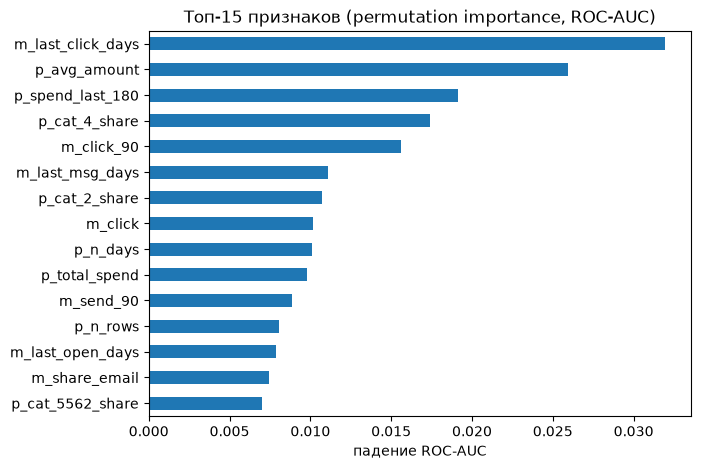

In [18]:
ax = imp.head(15)[::-1].plot(kind="barh", figsize=(7, 5),
                             title="Топ-15 признаков (permutation importance, ROC-AUC)")
ax.set_xlabel("падение ROC-AUC")

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Перестановочная важность по ROC-AUC вместо встроенной — верный выбор: она показывает реальный вклад признака в целевую метрику. График читается легко, а топ (давность клика, размах истории, покупки из рассылок, recency) выглядит логично.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> - Важность посчитана на тесте; чтобы тест оставался «чистым», лучше считать её на валидации или out-of-fold.
- Она посчитана только для бустинга, а финальная модель — ансамбль.
- Многие признаки сильно коррелируют (`p_n_tx`, `p_total_qty`, `p_n_days`, окна), и при перестановке одного остальные его «подменяют», поэтому важность каждого занижена. Можно группировать коррелированные признаки или посмотреть SHAP — заодно увидишь направление влияния (например, чем свежее клик, тем выше вероятность), что пригодится для объяснения модели бизнесу.
</div>

<div class="alert alert-info">
<b>Комментарий студента — отработка замечания v1</b><br>
Permutation importance теперь считается для выбранного варианта (включая ансамбль, если выбран он) на валидационных фолдах train и усредняется. Тест не используется. Ограничение из-за корреляции признаков указано в тексте; причинное направление влияния из permutation importance не выводится.
</div>

## 12. Проверка на утечку

Проверяем временные границы в функциях, уникальность клиентов и непересечение train/test.
Таргет и `client_id` исключены из признаков, более поздние агрегаты кампаний не используются.
Дополнительно считаем AUC отдельных признаков **только на train** с учётом обратной зависимости.
Для этой диагностики пропуски заменяем медианой train и отдельно проверяем индикатор пропуска.

Ни умеренный итоговый AUC, ни отсутствие «идеального» одиночного признака не доказывают
отсутствие утечки: её нужно исключать по происхождению данных. Проверки ниже служат
дополнительной диагностикой. Известная дата среза должна совпадать с датой формирования таргета.

In [19]:
single = {}
for col in X_tr.columns:
    values = X_tr[col]
    filled = values.fillna(values.median() if values.notna().any() else 0)
    auc = roc_auc_score(y_tr, filled)
    single[col] = max(auc, 1 - auc)
    if values.isna().any():
        auc = roc_auc_score(y_tr, values.isna().astype(int))
        single[col + "__missing"] = max(auc, 1 - auc)
display(pd.Series(single).sort_values(ascending=False).head(10).round(4))

m_last_click_days    0.7133
m_click_90           0.6962
p_recency_days       0.6486
p_rows_last_365      0.6335
m_click              0.6334
p_n_rows             0.6325
p_total_qty          0.6319
m_last_open_days     0.6225
m_open_90            0.6184
p_rows_last_180      0.6176
dtype: float64

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Отличная идея — проверка AUC каждого признака по отдельности с учётом обратной зависимости. Ни один признак не даёт больше 0.68, плюс в топе важности — поведенческие признаки, а не что-то «знающее будущее»: аргументация отсутствия утечки убедительная. Такой проверки в проектах почти не встретишь, здорово, что ты до неё додумался(ась).
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Мелочь: `roc_auc_score` уже импортирован в начале, повторный импорт под псевдонимом `_auc` не нужен. И эту проверку тоже лучше делать на train, а не на тесте.
</div>

<div class="alert alert-info">
<b>Комментарий студента — отработка замечания v1</b><br>
Повторный импорт убран. AUC одиночных признаков и индикаторов пропусков проверяется на train. Добавлено пояснение, что это диагностика, а не доказательство отсутствия утечки.
</div>

## 13. Выводы и бизнес-интерпретация

Итоговые метрики, важность признаков и охват покупателей формируются из результатов
исправленного запуска в ячейке ниже. Для рассылок оцениваем топ-10% и топ-20% клиентов:
`recall@k` — доля всех будущих покупателей, попавших в сегмент;
`precision@k` — доля покупателей среди выбранных; `lift@k` — отношение этой доли к базовой.
При случайном отборе ожидаемый охват равен доле выбранных клиентов, а lift равен 1.
Это оценка склонности к покупке, **не** причинного прироста покупок от рассылки.

**Как использовать.** Зафиксировать дату среза, построить признаки по доступной к ней истории
и ранжировать весь сопоставимый пакет клиентов. При выборе ансамбля его скор является
относительным рангом в пакете. Порог и бюджет рассылки выбирать на train OOF, не подбирать
по тесту. Для одиночного онлайн-скоринга ансамбль требует отдельного преобразования по
фиксированному эталонному распределению. Проверку эффекта рассылки проводить A/B-тестом.

**Ограничения и развитие.** Нужны идентификаторы заказов/товаров для решения вопроса совпадающих
покупок, словарь категорий, подтверждение единиц низких цен и протокола формирования таргета.
Полезны исторические срезы с покупками следующих 90 дней для временной проверки, отдельный
новый временной hold-out, калибровка и отбор групп коррелированных признаков. Агрегаты кампаний
можно подключать только после временной фильтрации и клиентской привязки.

In [20]:
def business_metrics(y_true, scores, shares=(.1, .2)):
    truth = np.asarray(y_true)
    order = np.argsort(-np.asarray(scores), kind="stable")
    prevalence = truth.mean()
    rows = []
    for share in shares:
        k = int(np.ceil(len(truth) * share))
        buyers = truth[order[:k]].sum()
        actual_share = k / len(truth)
        rows.append({"Сегмент": f"Топ-{share:.0%}", "Клиентов": k,
                     "Покупателей": int(buyers), "Доля сегмента": actual_share,
                     "Recall": buyers / truth.sum(), "Precision": buyers / k,
                     "Lift": (buyers / k) / prevalence,
                     "Ожидаемый recall случайного отбора": actual_share})
    return pd.DataFrame(rows)

business = business_metrics(y_te, test_score)
display(business.round(4))
top_features = ", ".join(f"`{col}`" for col in imp.head(5).index)
text = (f"**Результат.** По среднему train CV выбрана **{selected_name}** "
        f"(ROC-AUC {cv_comparison.loc[selected_name, 'mean_auc']:.4f}, "
        f"стандартное отклонение {cv_comparison.loc[selected_name, 'std_auc']:.4f}). "
        f"На ранее просматривавшемся hold-out: **ROC-AUC {test_auc:.4f}**. "
        f"Первые пять признаков по CV permutation importance: {top_features}. ")
for _, row in business.iterrows():
    text += (f"**{row['Сегмент']}** охватывает {row['Recall']:.1%} покупателей "
             f"при precision {row['Precision']:.1%}; lift **{row['Lift']:.2f}**. ")
display(Markdown(text))

,Сегмент,Клиентов,Покупателей,Доля сегмента,Recall,Precision,Lift,Ожидаемый recall случайного отбора
0,Топ-10%,997,81,0.1,0.4219,0.0812,4.2188,0.1
1,Топ-20%,1994,111,0.2,0.5781,0.0557,2.8906,0.2


**Результат.** По среднему train CV выбрана **Ensemble** (ROC-AUC 0.7683, стандартное отклонение 0.0148). На ранее просматривавшемся hold-out: **ROC-AUC 0.7714**. Первые пять признаков по CV permutation importance: `m_last_click_days`, `p_avg_amount`, `p_spend_last_180`, `p_cat_4_share`, `m_click_90`. **Топ-10%** охватывает 42.2% покупателей при precision 8.1%; lift **4.22**. **Топ-20%** охватывает 57.8% покупателей при precision 5.6%; lift **2.89**. 

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> - В выводах среди самых важных признаков назван «средний чек», но в топ-15 перестановочной важности его нет (там `p_min_price`). Выводы должны опираться на полученные результаты — сверь формулировки с таблицей.
- ROC-AUC = 0.77 маркетологу мало что скажет. Добавь бизнес-интерпретацию: например, какую долю будущих покупателей ловят топ-10% / топ-20% клиентов по скору модели и во сколько раз это лучше случайной рассылки (lift). Это сделает блок «Как использовать» гораздо убедительнее.
- Список возможных улучшений хороший и конкретный — видно, что ты понимаешь, куда развивать решение дальше.
</div>

<div class="alert alert-info">
<b>Комментарий студента — отработка замечания v1</b><br>
Вывод с перечнем важных признаков формируется автоматически из новой таблицы CV permutation importance. Добавлены recall, precision и lift для топ-10%/20% выбранной модели и их бизнес-интерпретация.
</div>

<div style="border:solid Chocolate 2px; padding: 40px">

**Общий вывод по проекту ревьювера v1**:

Спасибо за проект! Работа сделана на хорошем уровне и выглядит как решение человека, который понимает, зачем нужен каждый шаг: код чистый, решения обоснованы, а итоговый ROC-AUC ≈ 0.77 получен без утечек. Осталось подтянуть пару методологических моментов.

**Отмечу положительные моменты**:

1. Внимание к утечке на протяжении всего проекта: обоснованная временная граница, признаки строго до точки среза и отдельная проверка AUC одиночных признаков в конце.

2. Богатый и продуманный набор признаков: RFM со скользящими окнами и трендом, устойчивая к смене вложенности обработка категорий, поведенческие признаки по рассылкам.

3. Инженерная зрелость: чанковая обработка 1.4 ГБ файла с корректным объединением агрегатов, функции признаков, параметризованные точкой среза и готовые к переиспользованию.

4. Правильная схема валидации, тюнинг от гипотезы и ранговый ансамбль моделей разной природы.

**На что стоит обратить внимание**:

1. Провести полноценный исследовательский анализ данных: дубликаты, аномалии, распределения, обзор таблицы рассылок и агрегатов кампаний — с выводами.

2. Подтвердить выбор ансамбля на кросс-валидации по train и только после этого один раз оценить его на тесте.

**Рекомендации** (по желанию): пропуски вместо нулей и 9999 для бустинга, логарифмирование признаков для логрегрессии, бизнес-интерпретация метрики через lift / долю покупателей в топе скоринга.

**Удачи и жду твой проект на повторное ревью!**
</div>

<div class="alert alert-info">
<b>Комментарий студента — отработка замечания v1</b><br>
Обязательные замечания по EDA и выбору модели отработаны в коде и выводах. Рекомендации по путям, пропускам, категориям, CV-важности и бизнес-метрикам также учтены.
</div>